# Vessels: structures, calibre and wall expression

## Motivation

The FICTURE decode labels every 2 µm pixel of a Visium HD section with a Level-3 cell type of the heart atlas. A
vessel, however, is not a pixel: it is a wall of endothelial and mural cells around a lumen, a few to a few hundred
micrometres across. To ask how the wall changes from capillaries to arteries, we first have to turn labelled
pixels into vessels.

In this notebook we join neighbouring vascular pixels into **vessel structures**, measure the **calibre** of each
structure, and then follow four read-outs along calibre and vessel type: the cell-type composition of the wall
(Fig 4 g), the marker genes of each wall compartment (Fig 4 h), the genes of the renin–angiotensin system (RAAS,
Fig 4 i–j) and the targets of vascular drug classes (Fig 4 k). Two fields on the H&E image show what an arteriole
and a venule look like at this resolution (Fig 4 f).

## Dataset

We work with 11 Visium HD sections of the human left ventricle: eight sections from Berlin and three AH sections.
For every section the cell-typing pipeline (`scripts/substrate/`) has written the objects we start from:

| object | content | fields used here |
|---|---|---|
| FICTURE pixel decode (`.pixel.tsv.gz`) | one row per decode pixel | `X`, `Y` (µm), `K1` (code of the most probable Level-3 type), `P1` (its probability) |
| Space Ranger 2 µm matrix (`square_002um`) | bins × features, raw counts | `X`, `var_names`, bin positions → `obsm["spatial"]` (µm) |
| 2 µm `AnnData` (`h5ad_2um`) | bins × genes with the FICTURE label | `X`, `obs["x_um"]`, `obs["y_um"]` |
| 8 µm CMFLAG-clean `AnnData` (`h5ad_8um_clean`) | 8 µm bins after the spillover clean-up | `obs["L3_label"]`, `obsm["spatial"]` |
| CMFLAG flags (`<section>_clean_bins.parquet`) | one row per 2 µm bin | the four spillover flags |

The analysis steps live in `hhca.tl` and the figure panels in `hhca.pl`; the command-line scripts in
`scripts/vascular/` and `figures/Fig4/` call the same functions on all sections.

## Environment setup

We load the packages and set the scanpy defaults; `style.notebook()` gives the plots of this notebook the font and
open axes of the figure panels. All paths in the configuration are relative to the repository
root, so we work from there.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import json
import os

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import squidpy as sq
import tifffile

import hhca
from hhca.config import fill, load_config, resolve_roots, section_path
from hhca.grid import spillover_keys
from hhca.pl import style

sc.settings.verbosity = 0
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)
style.notebook()
np.random.seed(0)
os.chdir(hhca.REPO)

Every parameter of the analysis is set in `config/vascular.yaml`. We read the file once and look at the values
that define structures, calibre classes and calibre bins; the gene lists are shown where they are used.

In [2]:
cfg = load_config("vascular")
sections = cfg["slides"]["berlin"] + cfg["slides"]["ah"]
vascular_types = cfg["structures"]["vascular_types"]
lattice_um = cfg["structures"]["lattice_um"]
parameters = pd.concat([pd.Series(cfg["structures"]), pd.Series(cfg["calibre"]), pd.Series(cfg["composition"])])
parameters.to_frame("value")

,value
vascular_types,"{'ArterialEC': 'Arterial Endothelial cells', '..."
lattice_um,8.0
min_votes,2
muscular_vsmc_fraction,0.1
large,"{'quantile': 0.9, 'min_vsmc_fraction': 0.2}"
small,"{'quantile': 0.33, 'max_vsmc_fraction': 0.05}"
diameter_bins,"{'low': 8.9, 'high': 220.0, 'n_edges': 18}"
size_bins,"{'low': 0.99, 'high': 400.0, 'n_edges': 18}"
min_structures,20


## Loading data

We walk through each step on one section, `VS_BO_HDZ150319_34_myo`, and then run it on all 11. The decode of a
section is a table with one row per pixel; `K1` indexes the list of Level-3 types in the order of the FICTURE
model.

In [3]:
section = "VS_BO_HDZ150319_34_myo"
with open(section_path(cfg, "factor_order")) as handle:
    factor_order = json.load(handle)

pixels = hhca.io.read_decode(section_path(cfg, "decode", section), columns=("X", "Y", "K1", "P1"))
pixels.head()

,X,Y,K1,P1
0,3299.699951,5650.399902,22,1.0
1,3305.800049,5662.399902,22,1.0
2,3309.600098,5598.399902,22,1.0
3,3309.600098,5604.399902,22,1.0
4,3309.899902,5694.399902,22,1.0


The five vascular types are a minority of the pixels of a myocardial section:

In [4]:
cell_type_of_code = pd.Series(factor_order)
share = pixels["K1"].value_counts(normalize=True).rename(index=cell_type_of_code)
vascular_share = 100 * share[list(vascular_types.values())]
vascular_share.round(2).to_frame("% of decode pixels")

,% of decode pixels
K1,
Arterial Endothelial cells,0.16
Capillary Endothelial cells,1.14
Venous Endothelial cells,0.14
Pericytes,1.26
Vascular Smooth Muscle cells,0.74


To see where these cells sit, we load the 8 µm CMFLAG-clean `AnnData` of the section and plot its Level-3 labels
in tissue coordinates, in the colours of the spatial panels (`style.SPATIAL`).

In [5]:
tissue = sc.read_h5ad(section_path(cfg, "h5ad_8um_clean", section))
tissue

AnnData object with n_obs × n_vars = 269543 × 18085
    obs: 'L3_label', 'L3_top1_frac', 'gcert_mean', 'n_2um_bins', 'n_2um_flagged', 'frac_counts_removed', 'x_um', 'y_um', 'slide'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'L3_composition_order', 'build', 'cmflag', 'slide'
    obsm: 'L3_composition', 'spatial'

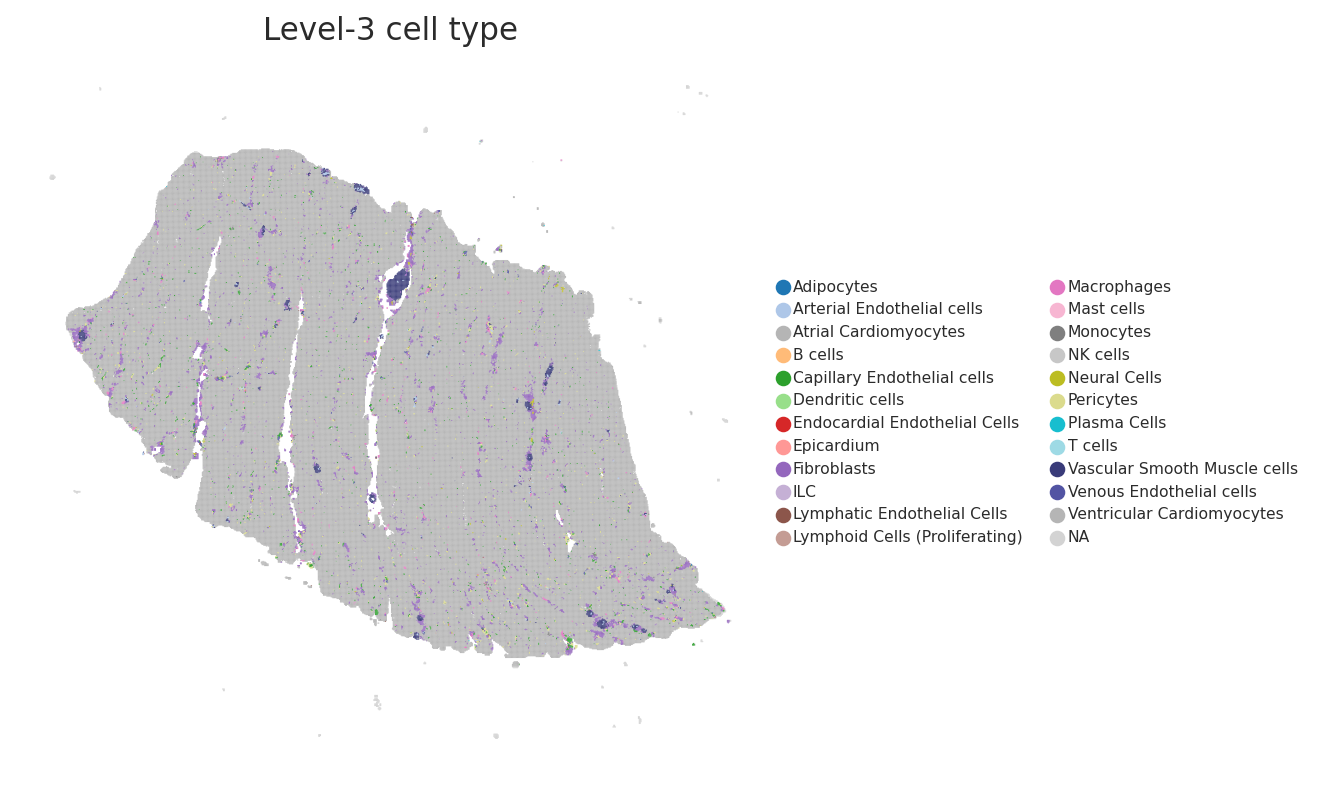

In [6]:
style.set_colors(tissue, "L3_label", style.SPATIAL)
with plt.rc_context({"figure.figsize": (6, 6)}):
    ax = sc.pl.embedding(
        tissue, basis="spatial", color="L3_label", size=1, legend_fontsize=7, title="Level-3 cell type", show=False
    )
ax.invert_yaxis()
ax.set_aspect("equal")
plt.show()

Cardiomyocytes fill the section; vascular cells form a fine network between them, with a few larger vessels.

## Vessel structures

A vessel wall is a few cells thick, so single 2 µm pixels are too small a unit. We therefore count, on a lattice
of 8 µm cells, how many decode pixels of each vascular type fall into every lattice cell (its *votes*) and keep
the cells with at least two vascular pixels. `hhca.tl.vascular_lattice` does this count and returns the vascular
lattice cells as an `AnnData`: observations are lattice cells, variables the five vascular types and `X` the
votes.

In [7]:
vessels = hhca.tl.vascular_lattice(
    pixels,
    factor_order,
    vascular_types,
    lattice_um=lattice_um,
    min_votes=cfg["structures"]["min_votes"],
)
vessels

AnnData object with n_obs × n_vars = 28771 × 5
    obs: 'key', 'gx', 'gy', 'n_votes', 'dom_subtype', 'x_um', 'y_um'
    var: 'cell_type', 'K1'
    obsm: 'spatial'

Neighbouring vascular cells belong to the same vessel. `hhca.tl.vessel_structures` labels the connected
components of the lattice (cells that touch by an edge or a corner) and adds the component id as
`vessels.obs["struct"]`.

In [8]:
hhca.tl.vessel_structures(vessels)
vessels.obs[["x_um", "y_um", "n_votes", "dom_subtype", "struct"]].head()

,x_um,y_um,n_votes,dom_subtype,struct
1980000775,1584.0,6200.0,2.0,CapillaryEC,1399
2000000778,1600.0,6224.0,10.0,CapillaryEC,1433
2000000779,1600.0,6232.0,4.0,CapillaryEC,1433
2050000771,1640.0,6168.0,2.0,CapillaryEC,1338
2050000776,1640.0,6208.0,2.0,CapillaryEC,1410


Let's look at a 600 µm window of the section (`notebook.lattice_window` in the configuration), with every lattice
cell coloured by its dominant vascular type.

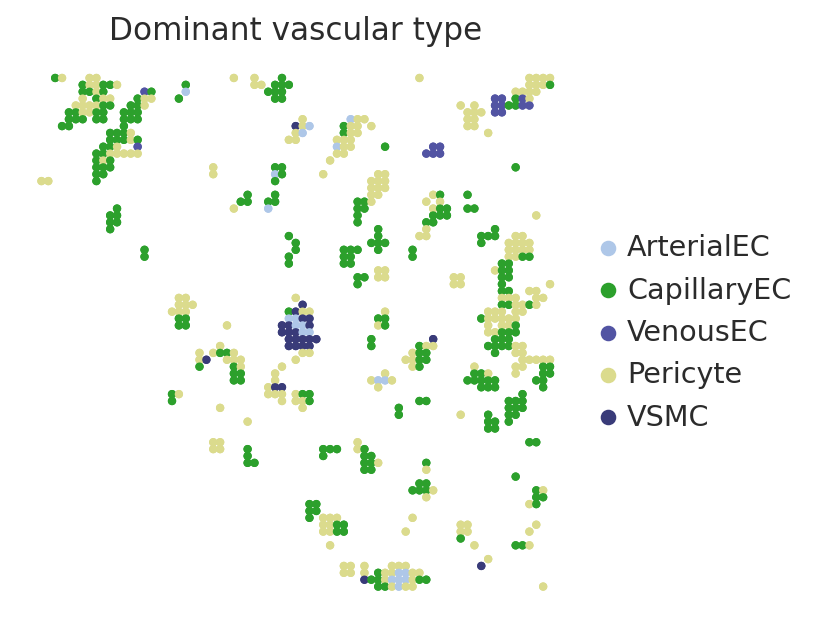

In [9]:
lattice_window = cfg["notebook"]["lattice_window"]
x, y = vessels.obsm["spatial"].T
inside = hhca.tl.in_window(x, y, lattice_window["centre_um"], lattice_window["half_size_um"])
window_cells = vessels[inside].copy()
vascular_colours = vessels.var["cell_type"].map(style.SPATIAL)  # short name of a vascular type -> colour
style.set_colors(window_cells, "dom_subtype", vascular_colours)
sq.pl.spatial_scatter(
    window_cells, color="dom_subtype", shape=None, size=30, figsize=(5, 5), title="Dominant vascular type"
)

Capillary endothelial cells and pericytes form short strings, while the smooth muscle cells cluster around a few
larger vessels.

Each structure is then summarised by `hhca.tl.structure_table`: its size, the share of its votes per type and a
vessel type. A structure with at least 10% smooth-muscle votes is a muscular artery or vein; otherwise its
dominant endothelial type makes it an arteriole, a venous vessel or a capillary/microvessel.

In [10]:
structures = hhca.tl.structure_table(
    vessels, muscular_vsmc_fraction=cfg["structures"]["muscular_vsmc_fraction"], lattice_um=lattice_um
)
structures[["struct", "n_bins", "frac_VSMC", "frac_CapillaryEC", "ec_identity", "vessel_type"]].head()

,struct,n_bins,frac_VSMC,frac_CapillaryEC,ec_identity,vessel_type
0,1,2,0.0,1.000000,Capillary,Capillary/microvessel
1,2,2,0.0,1.000000,Capillary,Capillary/microvessel
2,3,3,0.0,0.666667,Capillary,Capillary/microvessel
3,4,3,0.0,0.571429,Capillary,Capillary/microvessel
4,5,1,0.0,1.000000,Capillary,Capillary/microvessel


We now repeat the three calls on every section and keep the lattice of each section for the later steps.

In [11]:
vessels_by_section = {}
structures = []
for name in sections:
    section_pixels = hhca.io.read_decode(section_path(cfg, "decode", name))
    section_vessels = hhca.tl.vascular_lattice(
        section_pixels,
        factor_order,
        vascular_types,
        lattice_um=lattice_um,
        min_votes=cfg["structures"]["min_votes"],
    )
    hhca.tl.vessel_structures(section_vessels)
    table = hhca.tl.structure_table(section_vessels, cfg["structures"]["muscular_vsmc_fraction"], lattice_um)
    table.insert(0, "slide", name)
    vessels_by_section[name] = section_vessels
    structures.append(table)
structures = pd.concat(structures, ignore_index=True)
vessels = vessels_by_section[section]
n_sections = structures["slide"].nunique()
print(f"{len(structures):,} structures on {n_sections} sections")
structures["vessel_type"].value_counts().to_frame("structures")

87,792 structures on 11 sections


,structures
vessel_type,
Capillary/microvessel,80997
Arterial(muscular),3078
Arteriole,2284
Venous,1360
Venous(muscular),73


The 11 sections hold 87,792 vessel structures. Most of them, 80,997, are capillaries or microvessels; 3,078 are
muscular arteries, 2,284 arterioles, 1,360 venous vessels and 73 muscular veins.

## Calibre and calibre classes

The lattice cells of a large vessel trace its wall, not its lumen, so counting cells would underestimate its
size. `hhca.tl.vessel_calibre` takes the convex hull of a structure's cell centres (or the area of the cells
themselves, if that is larger) and reports the diameter of the circle with the same area.

In [12]:
calibre = []
for name in sections:
    table = hhca.tl.vessel_calibre(vessels_by_section[name], lattice_um=lattice_um)
    table.insert(0, "slide", name)
    calibre.append(table)
calibre = pd.concat(calibre, ignore_index=True)
calibre.head()

,slide,struct,n_bins,x_um,y_um,mural_VSMC_frac,filled_equiv_diam_um,hull_area_um2,lumen_equiv_diam_um
0,VS_BO_2024BH-008_myo,1,3,3629.333333,-1898.666667,0.0,15.635280,192.0,15.635280
1,VS_BO_2024BH-008_myo,2,2,3876.000000,-1892.000000,0.0,12.766153,128.0,12.766153
2,VS_BO_2024BH-008_myo,3,1,2768.000000,-1616.000000,0.0,9.027033,64.0,9.027033
3,VS_BO_2024BH-008_myo,4,1,2784.000000,-1584.000000,0.0,9.027033,64.0,9.027033
4,VS_BO_2024BH-008_myo,5,1,3896.000000,-1552.000000,0.0,9.027033,64.0,9.027033


We split the structures into three calibre classes. The cut points are the 33rd and 90th percentile of the
diameters on the eight Berlin sections and are applied to all 11 sections.

In [13]:
large_cfg = cfg["calibre"]["large"]
small_cfg = cfg["calibre"]["small"]
berlin_diameters = calibre.loc[calibre["slide"].isin(cfg["slides"]["berlin"]), "lumen_equiv_diam_um"]
large_cut_um = berlin_diameters.quantile(large_cfg["quantile"])
small_cut_um = berlin_diameters.quantile(small_cfg["quantile"])
large_percentile = 100 * large_cfg["quantile"]
small_percentile = 100 * small_cfg["quantile"]
print(f"D{small_percentile:.0f} = {small_cut_um:.1f} µm, D{large_percentile:.0f} = {large_cut_um:.1f} µm")

D33 = 9.0 µm, D90 = 22.1 µm


A large (conductance) vessel has a diameter of at least D90 and a muscular wall, a small (resistance) vessel a
diameter of at most D33 and almost no smooth muscle; everything else is intermediate. `hhca.tl.calibre_classes`
adds the class as `vessel_class`.

In [14]:
calibre = hhca.tl.calibre_classes(
    calibre,
    large_cut_um,
    small_cut_um,
    large_min_vsmc=large_cfg["min_vsmc_fraction"],
    small_max_vsmc=small_cfg["max_vsmc_fraction"],
)
calibre["vessel_class"].value_counts().to_frame("structures")

,structures
vessel_class,
intermediate,47814
small_resistance,38883
large_conductance,1095


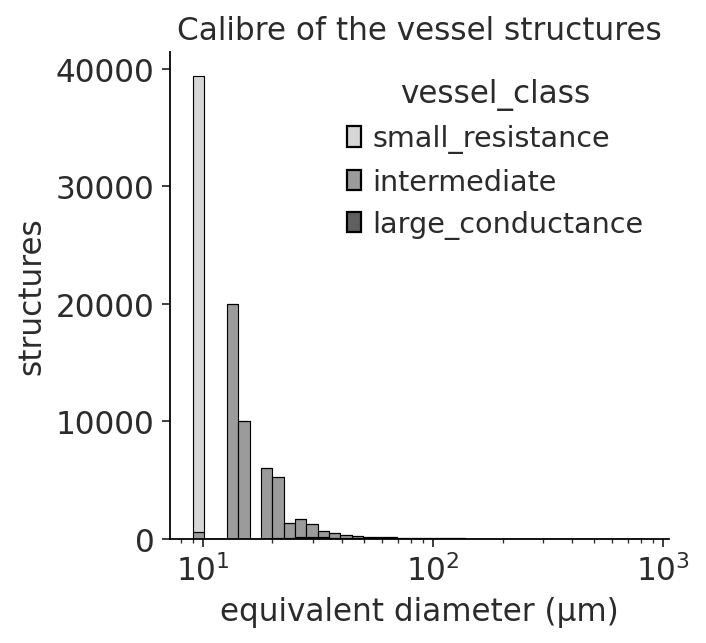

In [15]:
ax = sns.histplot(
    calibre,
    x="lumen_equiv_diam_um",
    hue="vessel_class",
    hue_order=list(style.CALIBRE_CLASS),
    palette=style.CALIBRE_CLASS,
    log_scale=True,
    bins=40,
    multiple="stack",
)
ax.set(xlabel="equivalent diameter (µm)", ylabel="structures", title="Calibre of the vessel structures")
plt.show()

The cut points are D33 = 9.0 µm, the diameter of a single lattice cell, and D90 = 22.1 µm. With them, 38,883
structures are small, 47,814 intermediate and 1,095 large.

## Cell-type composition along calibre

Which cells make up the wall at each calibre? The composition of a structure is the share of its votes per
vascular type. Before we compute it, we remove the decode pixels that the CMFLAG clean-up flagged as transcript
spillover from cardiomyocytes or from the vessel wall. `hhca.tl.clean_votes` recounts the votes of every lattice
cell without the flagged 2 µm bins and stores them as `vessels.layers["clean"]`; the structures themselves and
their calibre do not change. `hhca.tl.structure_votes` then sums both counts per structure.

In [16]:
votes = []
for name in sections:
    spillover = spillover_keys(f"{cfg['flags']}/{name}_clean_bins.parquet")
    section_pixels = hhca.io.read_decode(section_path(cfg, "decode", name))
    hhca.tl.clean_votes(vessels_by_section[name], section_pixels, spillover, lattice_um=lattice_um)
    table = hhca.tl.structure_votes(vessels_by_section[name])
    table.insert(0, "slide", name)
    votes.append(table)
votes = pd.concat(votes, ignore_index=True)
kept_share = vessels.layers["clean"].sum() / vessels.X.sum()
print(f"{kept_share:.1%} of the vascular pixels of {section} are kept")

94.7% of the vascular pixels of VS_BO_HDZ150319_34_myo are kept


We join the clean votes to the calibre table and look at the mean composition of the three calibre classes.

In [17]:
composition = hhca.tl.structure_composition(calibre, votes)
hhca.tl.composition_by_class(composition)

,frac_VSMC,frac_Pericyte,frac_ArterialEC,frac_CapillaryEC,frac_VenousEC,n_structures,median_diam_um
vessel_class,,,,,,,
large_conductance,53.64,14.71,21.16,9.75,0.75,1095,36.11
intermediate,2.18,40.90,2.14,53.31,1.47,47814,15.64
small_resistance,0.10,34.83,1.68,62.42,0.96,38883,9.03


The classes are coarse, so we also follow the composition along the diameter itself, in bins of equal width on
the log scale. `hhca.tl.composition_by_calibre` returns the mean share of each type per bin with the 95%
confidence interval of the mean.

In [18]:
diameter_bins = cfg["composition"]["diameter_bins"]
edges = np.geomspace(diameter_bins["low"], diameter_bins["high"], diameter_bins["n_edges"])
bins = hhca.tl.composition_by_calibre(
    composition, "lumen_equiv_diam_um", edges, min_structures=cfg["composition"]["min_structures"], name="diam_um"
)
bins[["median_diam_um", "n", "enough", "VSMC (mural)__pct", "Pericyte (mural)__pct", "Capillary EC__pct"]]

,median_diam_um,n,enough,VSMC (mural)__pct,Pericyte (mural)__pct,Capillary EC__pct
0,9.027033,39439,True,1.288,34.426,61.671
1,12.766153,19956,True,1.124,37.811,58.551
2,15.635280,10046,True,1.278,41.832,53.838
3,18.054067,6075,True,1.469,45.645,49.479
4,20.185060,5245,True,1.937,45.784,47.883
5,25.532306,3028,True,3.871,43.918,45.122
6,29.939283,1534,True,6.396,40.087,43.751
7,36.108133,959,True,10.214,37.997,39.428
8,43.292131,551,True,13.485,34.219,37.517
9,52.829006,288,True,18.040,28.986,37.554


Bins with fewer than 20 structures are not drawn. `hhca.pl.composition_along_calibre` draws Fig 4 g from this
table.

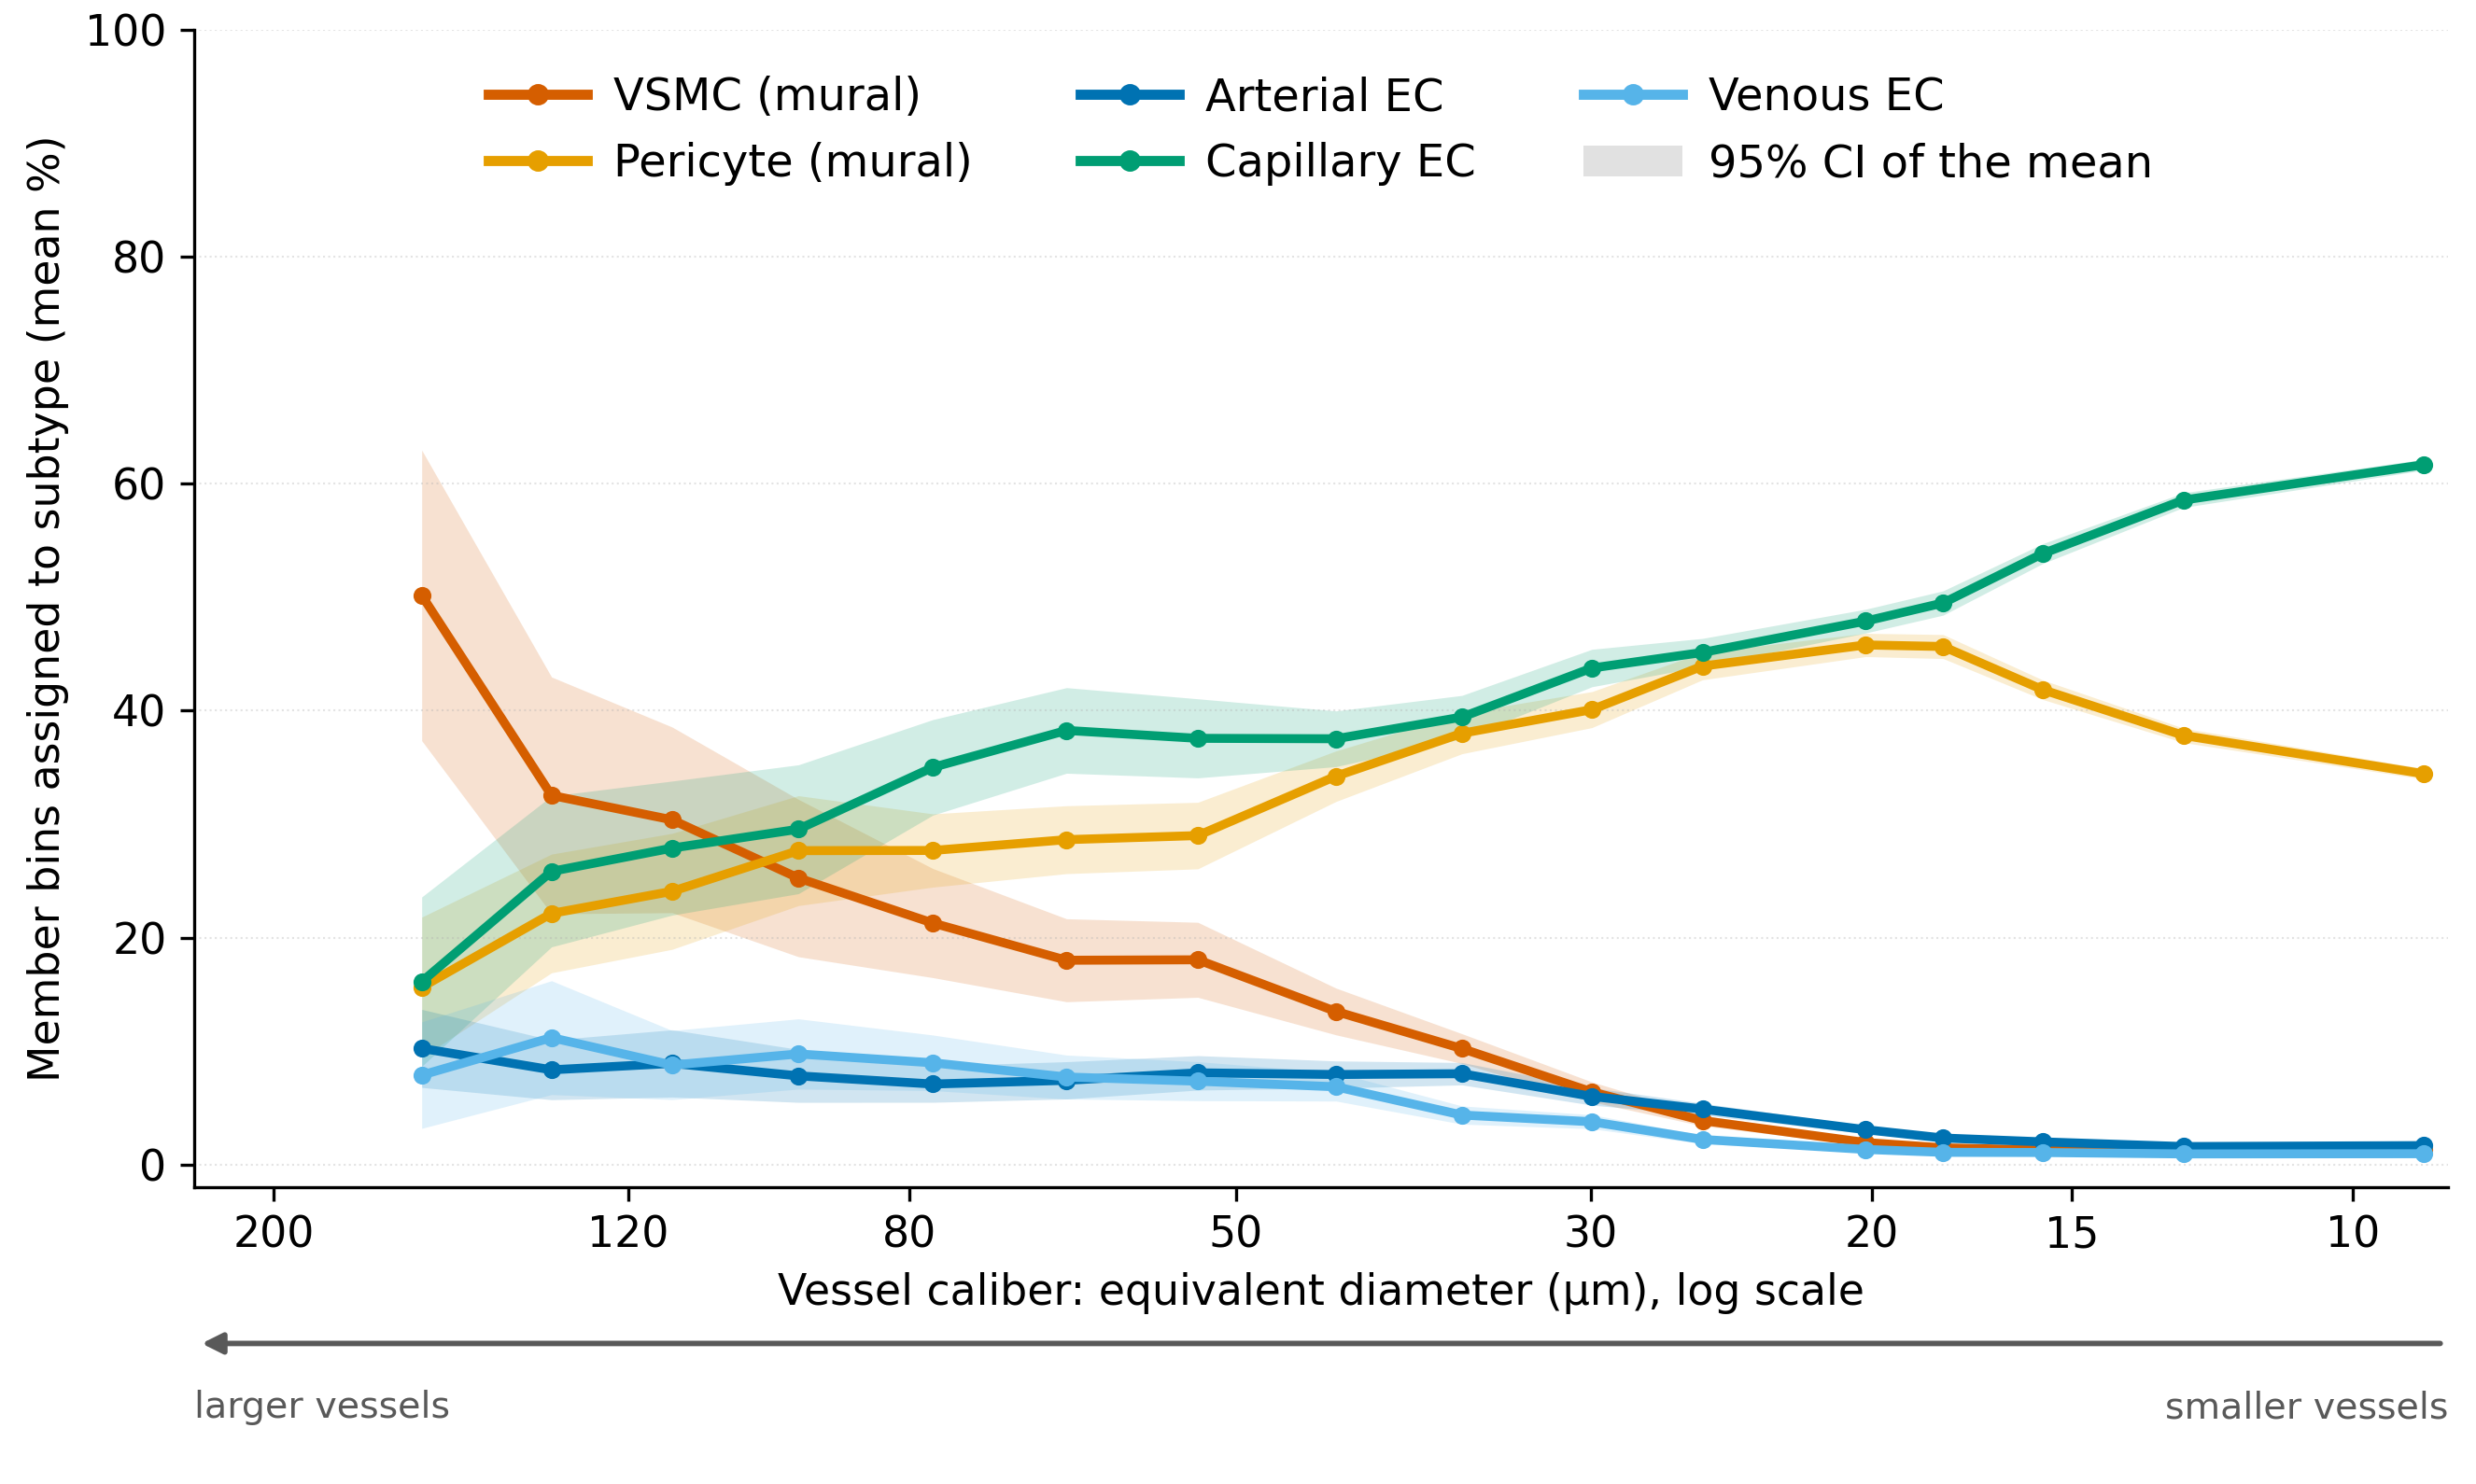

In [19]:
fig = hhca.pl.composition_along_calibre(bins, edges)

The wall changes continuously with calibre. Large vessels are mostly smooth muscle (53.6%) and arterial
endothelium (21.2%), small vessels capillary endothelium (62.4%) and pericytes (34.8%). Along the diameter, the
smooth-muscle share rises from 1.3% in the smallest bin to 50.2% at 162 µm, while the capillary share falls from
61.7% to 16.1%.

## Marker genes of the wall compartments

The decode tells us which cell type a pixel belongs to; the Space Ranger matrix tells us what is expressed there.
To describe the wall in genes, we assign the 2 µm bins of a section to wall compartments and sum the counts of
marker genes per compartment. We do this on our example section and load the 2 µm bins with their counts.

In [20]:
adata = hhca.io.read_visium_hd(section_path(cfg, "spaceranger", section))
adata

AnnData object with n_obs × n_vars = 4273635 × 18085
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'microns_per_pixel'
    obsm: 'spatial'

`hhca.tl.wall_compartments` gives every 2 µm bin the Level-3 type of its most probable decode pixel and keeps the
bins of the seven vessel-wall types. Capillary endothelial bins are split by whether a pericyte bin lies within
6 µm, and all bins inside a muscular vein form one more compartment. Bins flagged by CMFLAG are left out.

In [21]:
markers = cfg["markers"]
spillover = spillover_keys(f"{cfg['flags']}/{section}_clean_bins.parquet")
hhca.tl.wall_compartments(
    adata,
    pixels,
    factor_order,
    vessels,
    structures[structures["slide"] == section],
    markers["vessel_types"],
    spillover=spillover,
    pericyte_radius_um=markers["pericyte_radius_um"],
    lattice_um=lattice_um,
)
adata.obs["compartment"].value_counts().to_frame("2 µm bins")

,2 µm bins
compartment,
Pericytes,50542
Capillary EC (pericyte-),32506
Vascular Smooth Muscle cells,24388
Capillary EC (pericyte+),13878
Arterial Endothelial cells,6016
Venous Endothelial cells,4539
Lymphatic Endothelial Cells,2128
Endocardial Endothelial Cells,21


The function added `adata.obs["compartment"]` and `adata.obs["muscular_vein"]`. In a 300 µm window around the same
centre as before, the compartments now resolve the wall at 2 µm.

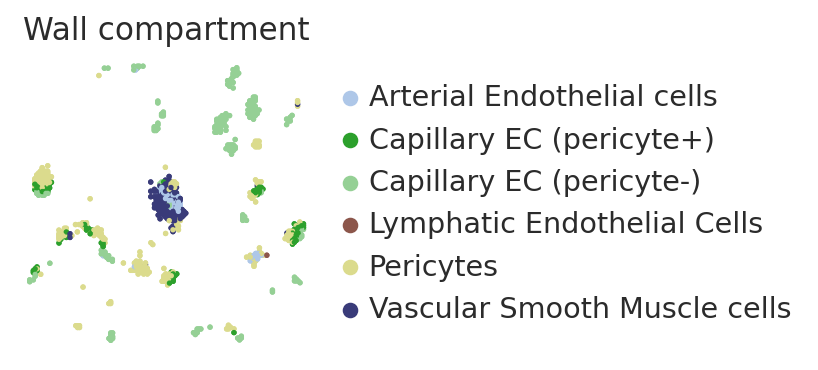

In [22]:
wall_window = cfg["notebook"]["wall_window"]
x, y = adata.obsm["spatial"].T
inside = hhca.tl.in_window(x, y, wall_window["centre_um"], wall_window["half_size_um"])
in_wall = adata.obs["compartment"].notna().to_numpy()
window_bins = adata[inside & in_wall].copy()
style.set_colors(window_bins, "compartment", style.WALL_COMPARTMENT)
sq.pl.spatial_scatter(window_bins, color="compartment", shape=None, size=8, figsize=(5, 5), title="Wall compartment")

The marker genes are the 25 genes of the vessel-wall panel plus every connexin and tight-junction gene of the
feature set. `hhca.tl.marker_counts` sums their counts over the bins of each compartment.

In [23]:
marker_genes = sorted(set(markers["panel"] + markers["connexins"] + markers["tight_junctions"]))
counts = hhca.tl.marker_counts(adata, marker_genes)
panel_genes = ", ".join(markers["panel"])
print(f"{len(marker_genes)} genes: {panel_genes}, ...")
counts.head()

83 genes: MYH11, ACTA2, SEMA3G, RGS5, ABCC9, CA4, RGCC, GPIHBP1, ACKR1, PLVAP, PROX1, LYVE1, NPR3, SMOC1, GJA5, GJA4, GJA1, GJC1, CLDN5, CDH5, TJP1, OCLN, F11R, CAV1, CAV2, ...


,type,gene,marker_sum,n_expr,n_bins,total_counts
0,Arterial Endothelial cells,ABCC9,12.0,11,6016,228424.0
1,Arterial Endothelial cells,ACKR1,1.0,1,6016,228424.0
2,Arterial Endothelial cells,ACTA2,309.0,287,6016,228424.0
3,Arterial Endothelial cells,CA4,1.0,1,6016,228424.0
4,Arterial Endothelial cells,CAV1,279.0,271,6016,228424.0


Reading the 2 µm matrix takes about a minute per section, so for the other ten sections we load the tables
written by `scripts/vascular/marker_aggregate.py`, which makes the same two calls. We pool the 11 sections per
compartment: `hhca.tl.pool_markers` returns counts per 10,000 (`cp10k`), the share of bins with a count (`pct`)
and `logcp = log1p(cp10k)`.

In [24]:
marker_tables = [pd.read_csv(f"results/vascular/markers/checkpoints/{name}.csv") for name in sorted(sections)]
per_section = pd.concat(marker_tables, ignore_index=True)
pooled = hhca.tl.pool_markers(per_section)
pooled[pooled["gene"] == "MYH11"]

,type,gene,marker_sum,n_expr,cp10k,pct,logcp
69,Arterial Endothelial cells,MYH11,3304.0,3153,19.619766,3.387372,3.026250
152,Capillary EC (pericyte+),MYH11,151.0,150,0.807104,0.142033,0.591725
235,Capillary EC (pericyte-),MYH11,293.0,289,0.446396,0.068024,0.369075
318,Endocardial Endothelial Cells,MYH11,17.0,17,3.764310,0.334580,1.561153
401,Lymphatic Endothelial Cells,MYH11,59.0,59,1.079744,0.056643,0.732245
484,Pericytes,MYH11,465.0,464,0.635536,0.103926,0.491970
567,Vascular Smooth Muscle cells,MYH11,47641.0,43852,99.009572,9.622470,4.605266
650,Venous EC (muscular vein),MYH11,1359.0,1287,50.473725,2.204862,3.941071
733,Venous Endothelial cells,MYH11,43.0,43,0.697332,0.087256,0.529058


Not every connexin of the feature set is expressed in the vessel wall. `hhca.tl.marker_detection` lists, per
gene, the compartment with the highest expression and whether the gene is detected at all.

In [25]:
detected_cfg = markers["detected"]
connexins = hhca.tl.marker_detection(
    pooled, markers["connexins"], min_counts=detected_cfg["min_counts"], min_pct=detected_cfg["min_pct"]
)
connexins[connexins["detected"]]

,gene,total_counts,n_expr,max_cp10k,max_pct,best_col,detected
14,GJC1,6999.0,6938,6.553536,1.063451,Pericytes,True
3,GJA4,6476.0,6428,4.939412,0.847649,Pericytes,True
4,GJA5,3783.0,3726,11.900124,2.106767,Arterial EC,True


`hhca.pl.wall_markers` draws Fig 4 h: the genes as rows, grouped by the compartment they mark, the compartments
as columns, and the expression of each gene z-scored over the compartments.

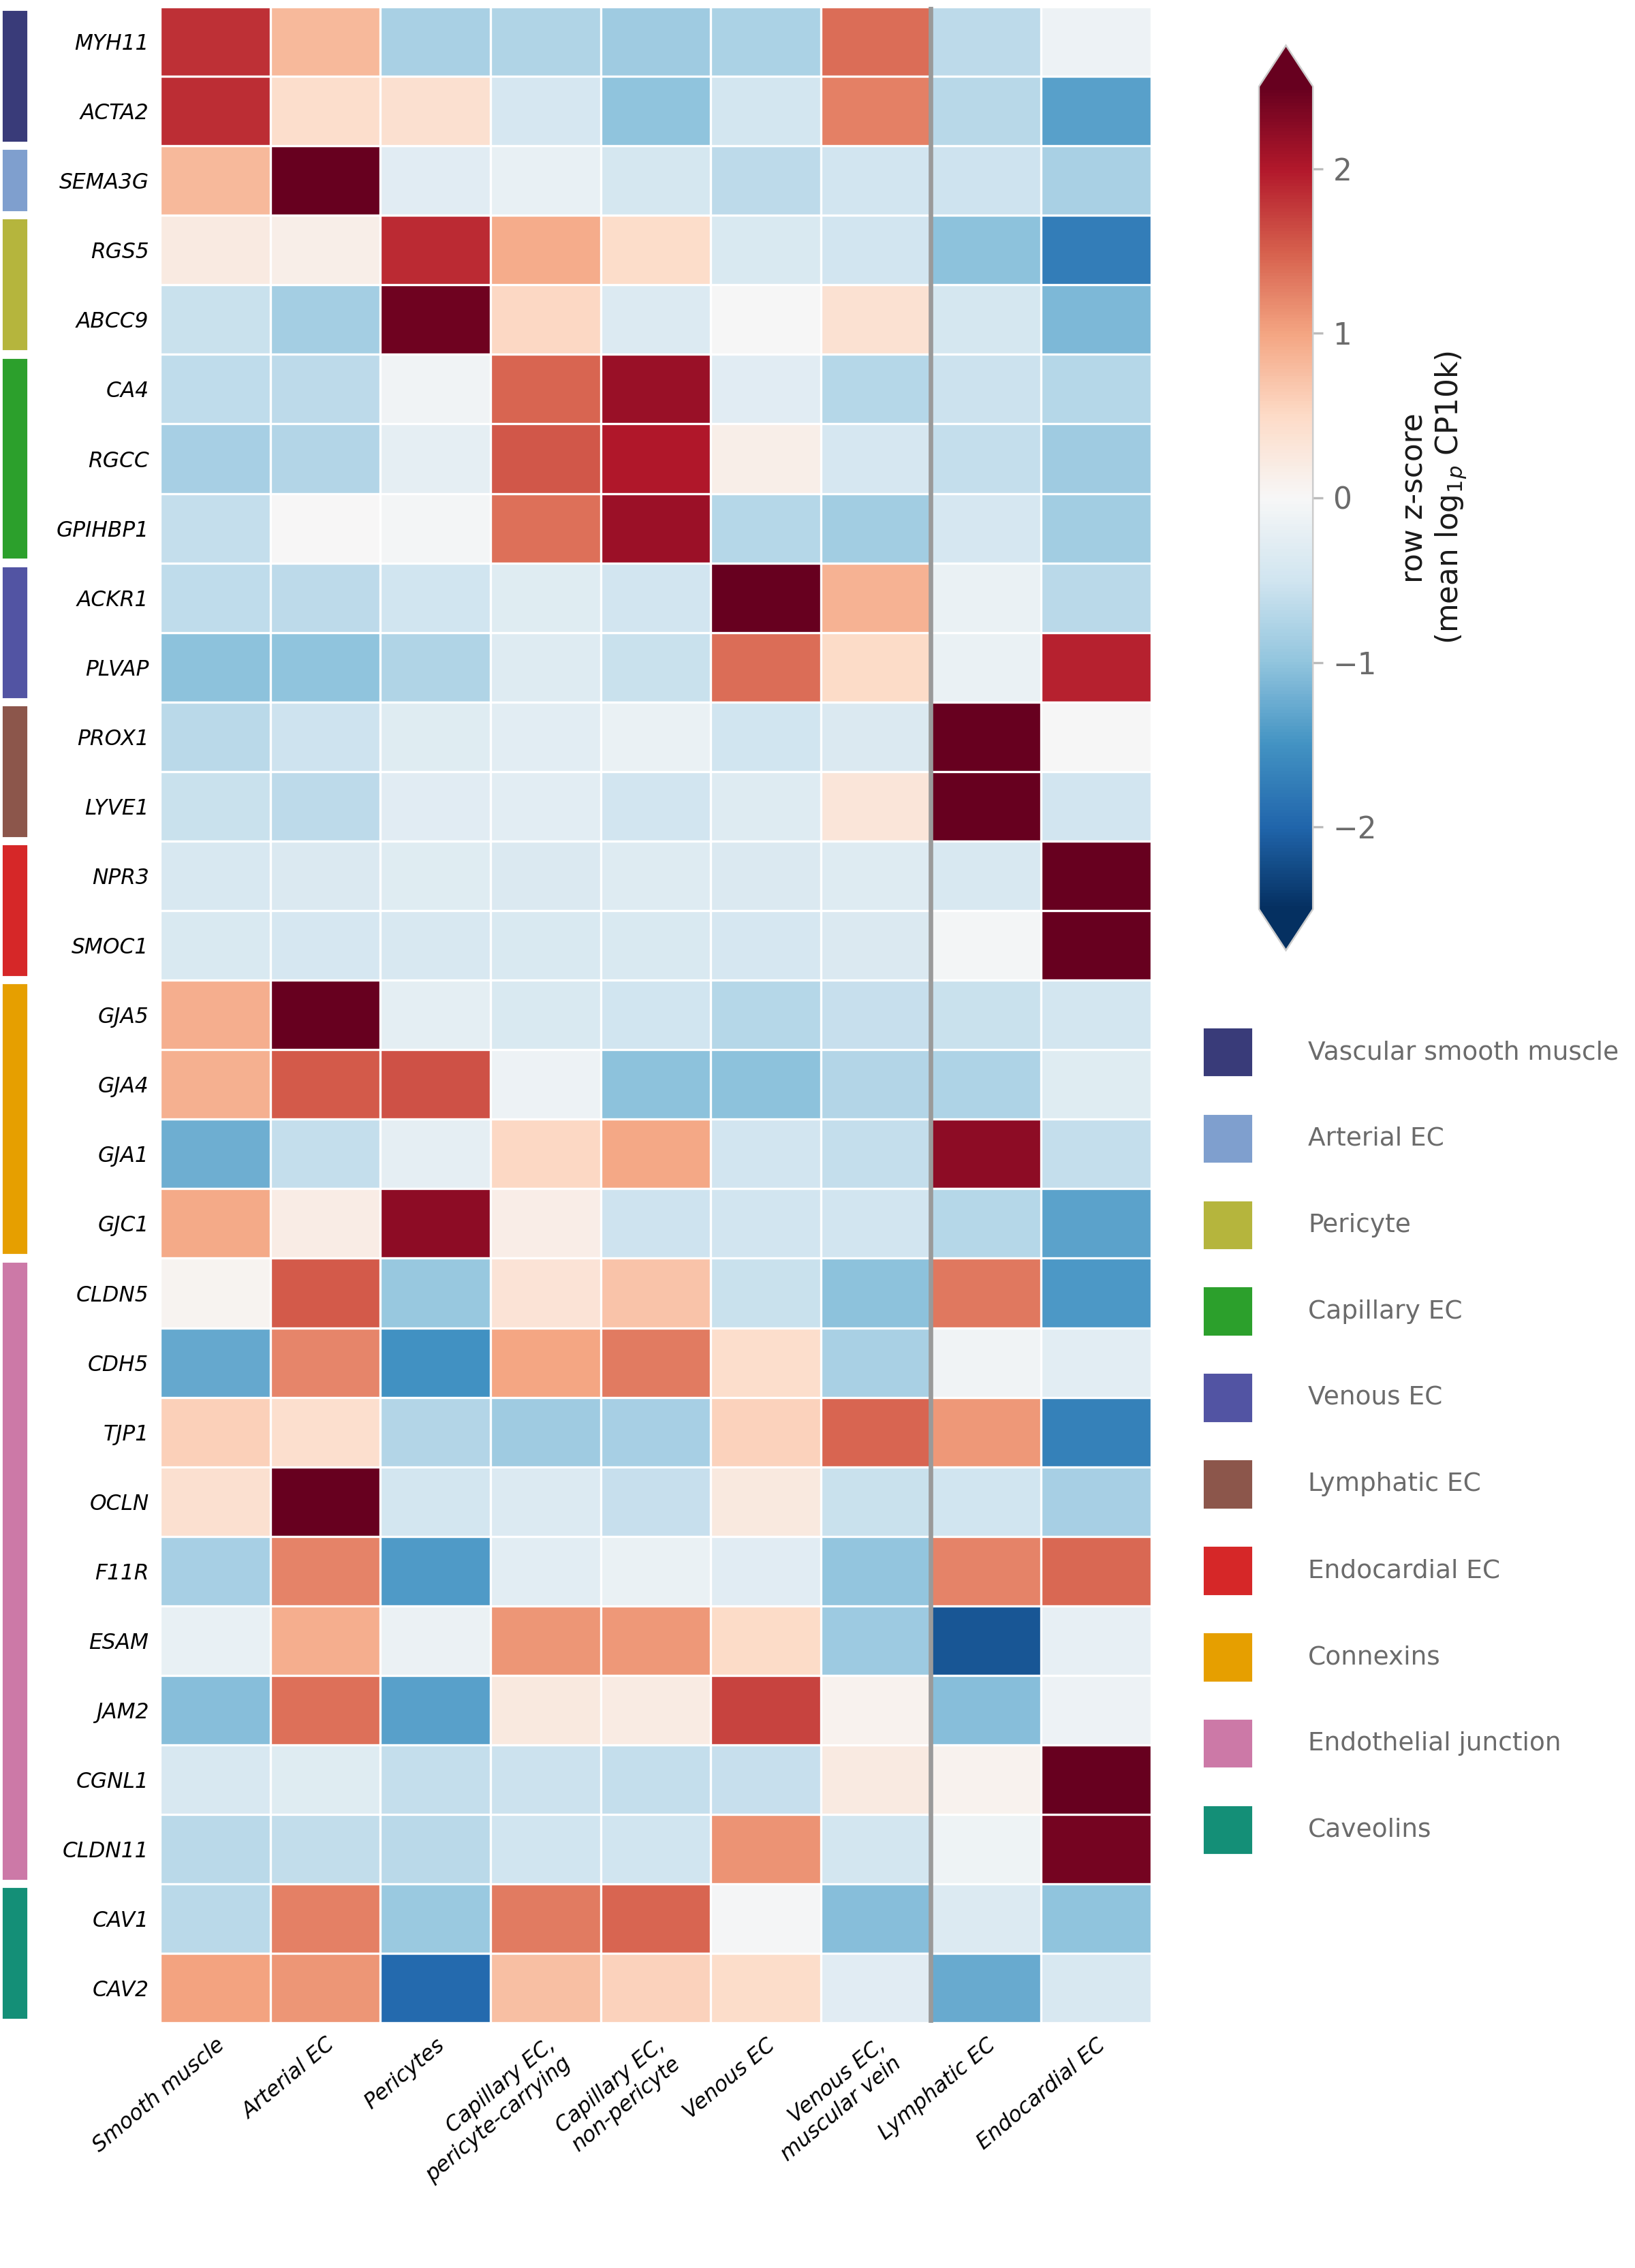

In [26]:
fig = hhca.pl.wall_markers(pooled)

The compartments express the genes expected of them. *MYH11*, for example, reaches 99.0 CP10k in smooth muscle
and 50.5 in the muscular-vein compartment, but stays below 1 CP10k in pericytes and capillary endothelium. Three
connexins are detected in the wall: *GJA5* is highest in arterial endothelium, *GJA4* and *GJC1* in pericytes.

## RAAS genes by vessel type

The renin–angiotensin system is the target of the most widely used cardiovascular drugs, so we ask which vessel
types express its enzymes and receptors. Here the unit is the vessel structure: we sum the counts of all 2 µm
bins of a structure into one pseudobulk profile.

`hhca.tl.lattice_counts` sums the RAAS genes and the library of each lattice cell. The library is restricted to
the 18,082 features that all 11 sections share, so that it means the same on every section, and flagged bins are
left out again.

In [27]:
raas = cfg["raas"]
raas_genes = raas["genes"] + raas["tf_up_in_agt_pos"] + raas["tf_up_in_rest"]
with open(cfg["resources"]["common_panel"]) as handle:
    panel = json.load(handle)

lattice = hhca.tl.lattice_counts(adata, raas_genes, panel=panel, spillover=spillover, lattice_um=lattice_um)
lattice[["tot", *raas["model_genes"]]].describe().loc[["count", "mean", "max"]]

,tot,AGT,ACE,ACE2,AGTR1,ENPEP
count,270012.000000,270012.00000,270012.000000,270012.000000,270012.000000,270012.000000
mean,350.195691,0.08123,0.005078,0.014255,0.000656,0.007485
max,2138.000000,9.00000,2.000000,3.000000,2.000000,3.000000


`hhca.tl.structure_pseudobulk` sums the lattice cells of each structure and joins the structure table.

In [28]:
pseudobulk = hhca.tl.structure_pseudobulk(lattice, vessels, structures[structures["slide"] == section])
pseudobulk[["struct", "vessel_type", "n_bins", "lib", *raas["model_genes"]]].head()

,struct,vessel_type,n_bins,lib,AGT,ACE,ACE2,AGTR1,ENPEP
0,1,Capillary/microvessel,2,575.0,0.0,0.0,0.0,0.0,0.0
1,2,Capillary/microvessel,2,362.0,0.0,0.0,0.0,0.0,0.0
2,3,Capillary/microvessel,3,402.0,0.0,0.0,0.0,0.0,0.0
3,4,Capillary/microvessel,3,1888.0,2.0,0.0,0.0,0.0,0.0
4,5,Capillary/microvessel,1,124.0,0.0,0.0,0.0,0.0,0.0


As for the markers, for the other ten sections we load the table written by `scripts/vascular/raas_substrate.py`,
which holds the structure pseudobulk of all 11 sections.

In [29]:
pooled_structures = pd.read_parquet("results/vascular/raas/pooled_struct_uniform.parquet")
print(f"all sections: {len(pooled_structures)} structures")

all sections: 87791 structures


Structures differ in how many transcripts they capture: large vessels are richer than capillaries, and sections
differ in depth. A raw mean per vessel type would mix these effects with expression. `hhca.tl.fit_raas` therefore
fits one linear model for the five genes jointly,

`log1p(CP10k) ~ gene × vessel type + gene × log library (centred) + gene × section (sum-coded)`,

with standard errors clustered by structure. Because the library is centred and the sections are sum-coded, the
`gene × vessel type` coefficients are marginal means at average richness, balanced over sections.

In [30]:
fit = hhca.tl.fit_raas(
    pooled_structures,
    raas["model_genes"],
    raas["vessel_types"],
    alpha=raas["alpha"],
    min_bins=raas["min_bins"],
    robust_fraction=raas["robust_fraction"],
)
n_fitted = len(fit["structures"])
print(f"{n_fitted} structures, design {fit['design_shape']}, full rank: {fit['full_rank']}")
adjusted_means = fit["emm"].pivot(index="gene", columns="vessel_type", values="adj_cp10k")
adjusted_means[raas["vessel_types"]].round(3)

87786 structures, design (438930, 80), full rank: True


vessel_type,Arterial(muscular),Arteriole,Capillary/microvessel,Venous,Venous(muscular)
gene,,,,,
ACE,0.156,0.346,0.049,0.031,0.039
ACE2,0.057,0.049,0.098,0.047,0.109
AGT,0.838,0.727,0.957,0.771,0.486
AGTR1,0.012,0.022,0.020,0.017,0.011
ENPEP,0.480,0.291,0.184,0.145,0.104


The function returns a dictionary of tables. `fit["emm"]` holds the adjusted mean of every gene and vessel type
with its confidence interval, and `fit["highest"]` tests, for each gene, the vessel type with the highest mean
against the second highest.

In [31]:
fit["highest"]

,gene,highest_vessel,second_vessel,diff_log1p_top_vs_2nd,p_fdr_top_vs_2nd,top_sig_gt_second
0,AGT,Capillary/microvessel,Arterial(muscular),0.062532,1.207839e-03,True
1,ACE,Arteriole,Arterial(muscular),0.152216,2.731310e-13,True
2,ACE2,Venous(muscular),Capillary/microvessel,0.009553,9.022511e-01,False
3,AGTR1,Arteriole,Capillary/microvessel,0.002821,6.125405e-01,False
4,ENPEP,Arterial(muscular),Arteriole,0.136549,2.551814e-11,True


`hhca.pl.raas_heatmap` shows the adjusted means of four genes as z-scores over the vessel types (Fig 4 i).

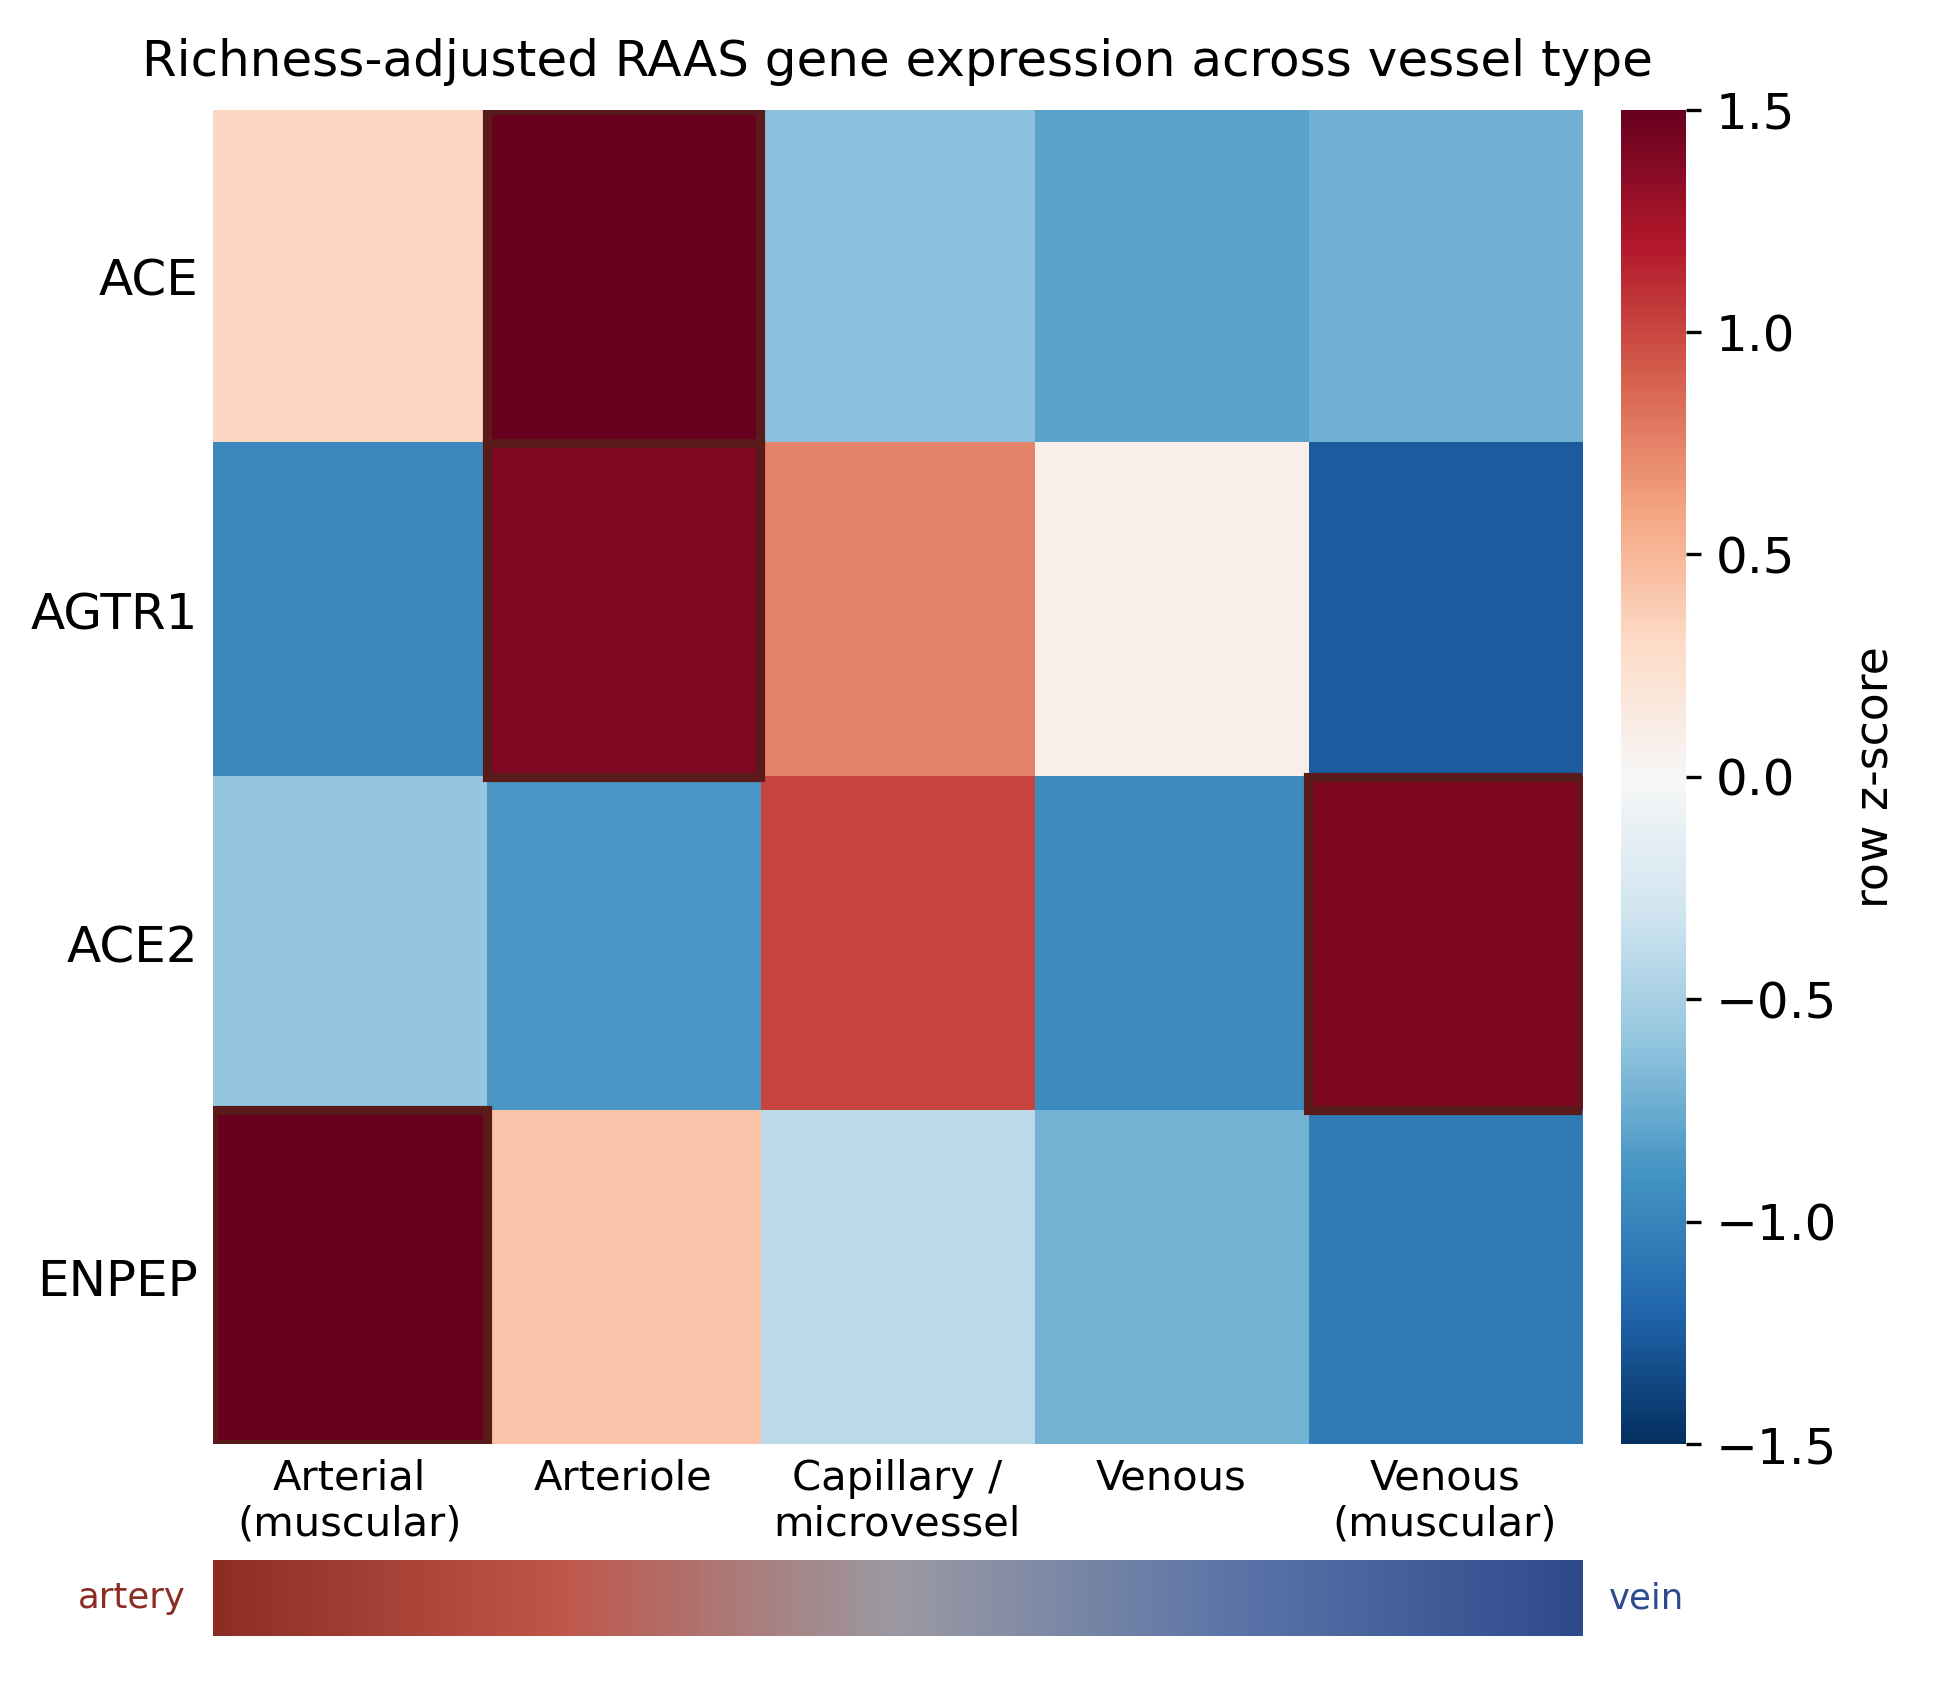

In [32]:
fig = hhca.pl.raas_heatmap(fit["emm"])

`hhca.pl.raas_means` shows the same means on the CP10k scale with their 95% intervals (Fig 4 j); AGT, which is
expressed at a higher level, is drawn on the right axis.

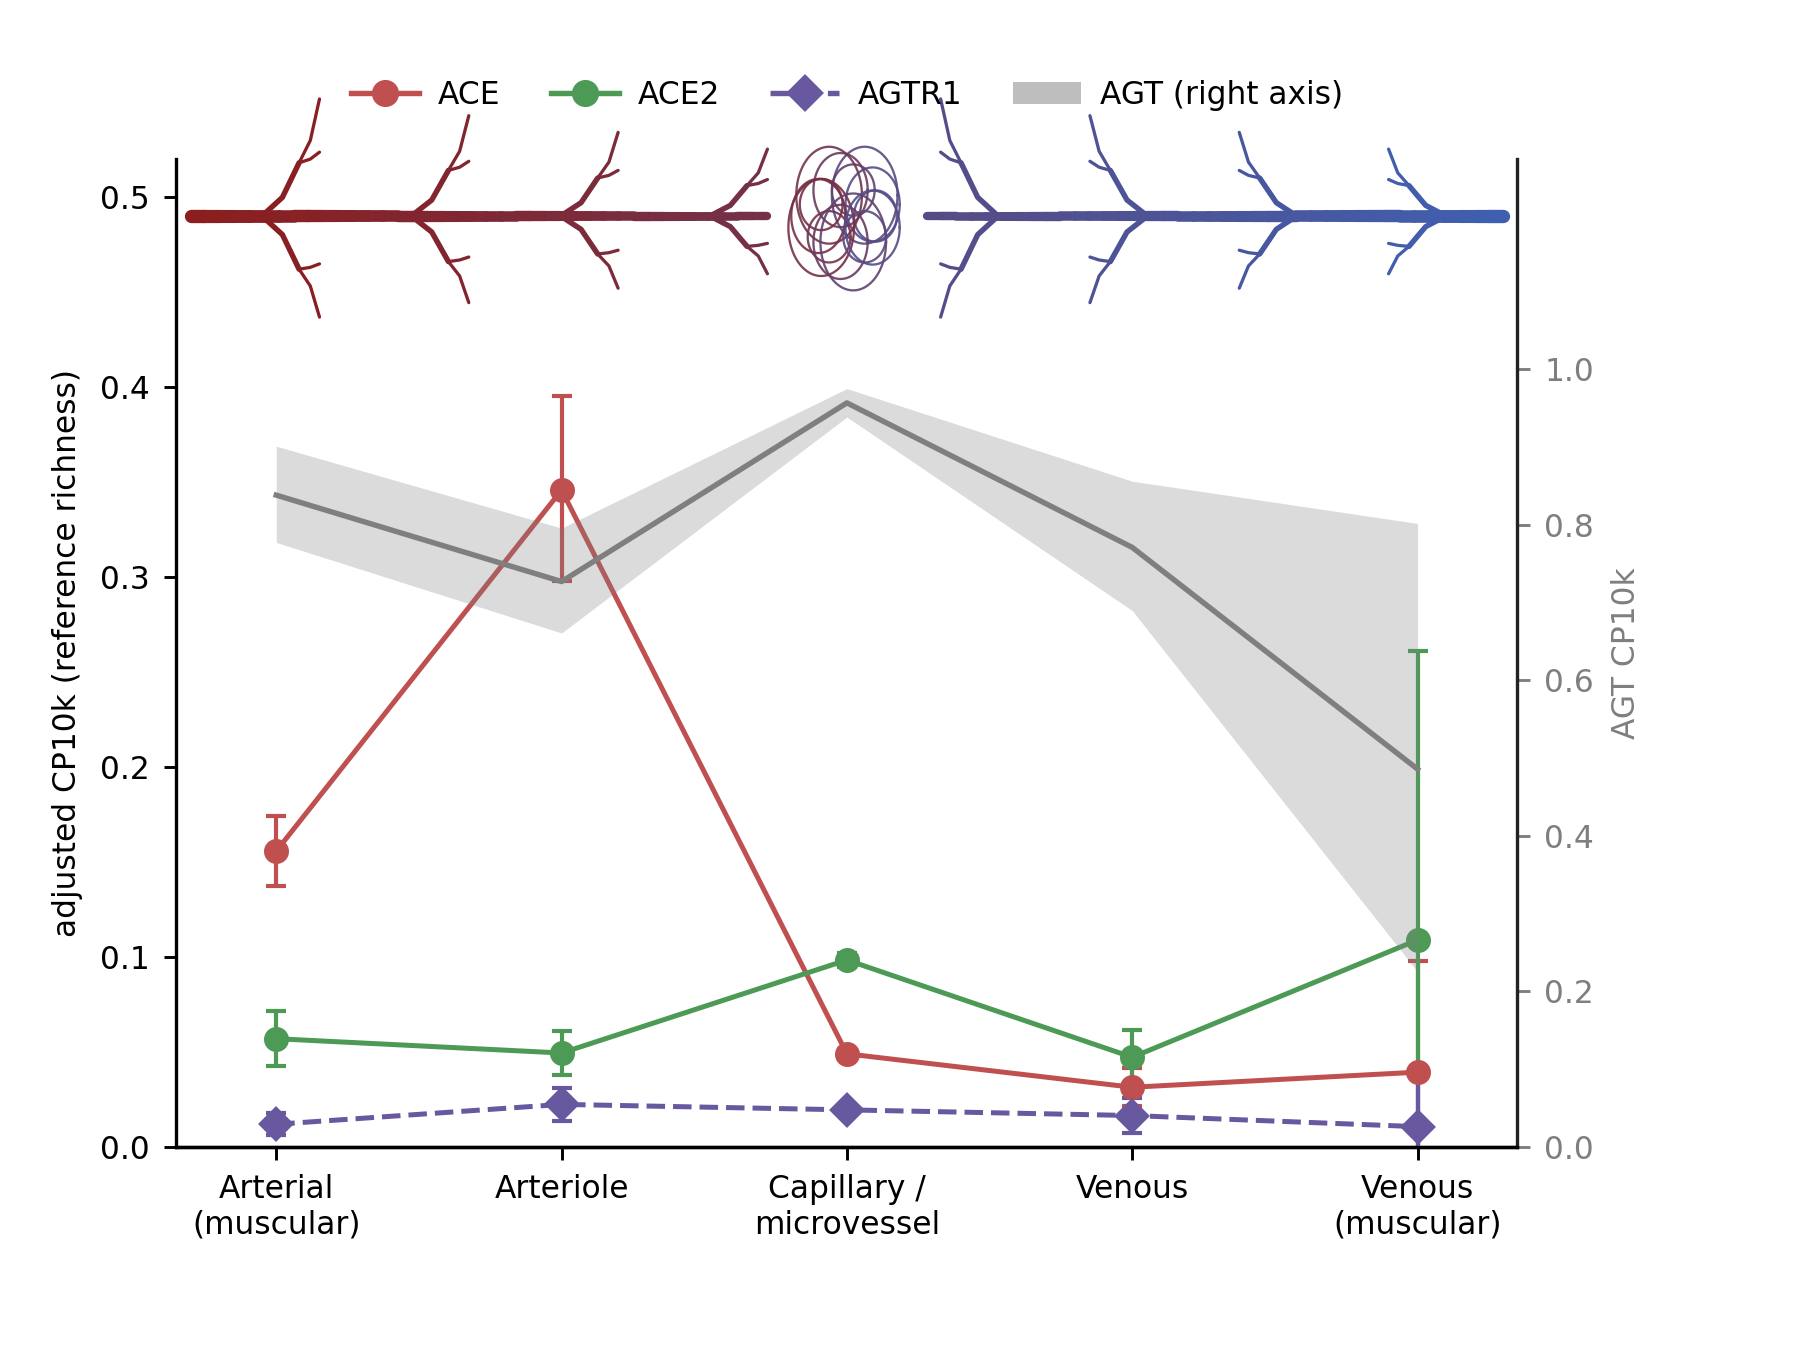

In [33]:
fig = hhca.pl.raas_means(fit["emm"])

The RAAS genes are not spread evenly over the vascular tree. *ACE* is highest in arterioles (0.346 adjusted CP10k,
against 0.156 in muscular arteries; FDR p = 2.7e-13) and *ENPEP* in muscular arteries (0.480; p = 2.6e-11). *AGT*
is expressed in every vessel type and is highest in capillaries and microvessels (0.957; p = 0.0012). *ACE2* and
*AGTR1* do not single out one vessel type (p = 0.90 and 0.61).

## Drug targets by calibre

Vasoactive drugs act on the wall, and the wall changes with calibre. For 11 drug classes we therefore compare
the expression of their target genes between large and small vessels. The classes and their targets are set in
the configuration:

In [34]:
drug = cfg["drug"]
classes = pd.DataFrame(drug["classes"]).T
classes

,genes,compartment
Endothelin receptor antagonists,"[EDNRA, EDNRB]",mural
Angiotensin receptor blockers,"[AGTR1, AGTR2]",mural
ACE inhibitors,[ACE],endothelial
Nitrates / NO-sGC,"[GUCY1A1, GUCY1A2, GUCY1B1]",mural
PDE5 inhibitors,[PDE5A],mural
PDE3 inhibitors,"[PDE3A, PDE3B]",mural
Calcium-channel blockers,"[CACNA1C, CACNA1D]",mural
Alpha-1 blockers,"[ADRA1A, ADRA1B, ADRA1D]",mural
Direct vasodilators (K-ATP),"[KCNJ8, ABCC9, KCNJ11]",mural
ROCK inhibitors,"[ROCK1, ROCK2]",mural


For this step the counts come from the 2 µm `AnnData` of the cell-typing pipeline, which is opened without
loading the matrix into memory.

In [35]:
bins_2um = ad.read_h5ad(section_path(cfg, "h5ad_2um", section), backed="r")
bins_2um

AnnData object with n_obs × n_vars = 4029508 × 18085 backed at 'results/substrate/h5ad_2um/VS_BO_HDZ150319_34_myo.h5ad'
    obs: 'L3_label', 'gcert', 'posterior_max', 'x_um', 'y_um', 'slide'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'build'

The library of a structure is summed over the genes that the Berlin and the AH gene panels share.

In [36]:
berlin_example, ah_example = cfg["slides"]["common_from"]
berlin_panel = ad.read_h5ad(section_path(cfg, "h5ad_2um", berlin_example), backed="r").var_names
ah_panel = ad.read_h5ad(section_path(cfg, "h5ad_2um", ah_example), backed="r").var_names
library_genes = berlin_panel.intersection(ah_panel)
drug_target_genes = classes["genes"].explode().tolist()
target_genes = list(dict.fromkeys(raas["genes"] + drug_target_genes))  # without repeats, in order
print(f"{len(library_genes)} library genes, {len(target_genes)} RAAS and drug-target genes")

18085 library genes, 32 RAAS and drug-target genes


`hhca.tl.pseudobulk_structures` maps every 2 µm bin to its structure and sums the library and the target genes
per structure, once over all bins (`*_raw`) and once without the flagged bins (`*_clean`). It reads the matrix in
blocks, so we can run it on all 11 sections.

In [37]:
structure_counts = []
for name in sections:
    section_bins = ad.read_h5ad(section_path(cfg, "h5ad_2um", name), backed="r")
    spillover = spillover_keys(f"{cfg['flags']}/{name}_clean_bins.parquet")
    table = hhca.tl.pseudobulk_structures(
        section_bins,
        vessels_by_section[name],
        spillover,
        target_genes,
        library_genes,
        lattice_um=lattice_um,
        chunk=drug["chunk_bins"],
    )
    table.insert(0, "slide", name)
    structure_counts.append(table)
structure_counts = pd.concat(structure_counts, ignore_index=True)
structure_counts[["slide", "struct", "libc_raw", "libc_clean", "ACE_clean", "PDE5A_clean"]].head()

,slide,struct,libc_raw,libc_clean,ACE_clean,PDE5A_clean
0,VS_BO_2024BH-008_myo,1,23.0,23.0,0.0,0.0
1,VS_BO_2024BH-008_myo,2,20.0,20.0,0.0,0.0
2,VS_BO_2024BH-008_myo,3,16.0,16.0,0.0,0.0
3,VS_BO_2024BH-008_myo,4,25.0,25.0,0.0,0.0
4,VS_BO_2024BH-008_myo,5,28.0,28.0,0.0,0.0


`hhca.tl.drug_class_scores` joins the calibre class and scores each drug class per structure as the mean
`log1p(CP10k)` of its target genes. We test the structures with a library of at least 50 counts.

In [38]:
scores = hhca.tl.drug_class_scores(structure_counts, calibre, drug["classes"], variant="clean")
tested = hhca.tl.tested_structures(scores, min_library=drug["min_library"])
tested["caliber"].value_counts().to_frame("structures tested")

,structures tested
caliber,
intermediate,45361
small_resistance,34083
large_conductance,1076


`hhca.tl.calibre_selectivity` compares large and small structures for each class with a linear model that
adjusts for library size and section, and corrects the p values over the 11 classes (Benjamini–Hochberg).

In [39]:
selectivity = hhca.tl.calibre_selectivity(tested, drug["classes"])
selectivity[
    ["drug_class", "mean_small_resistance", "mean_large_conductance", "coef_large_minus_small_adj", "p_adj_LvsS"]
]

,drug_class,mean_small_resistance,mean_large_conductance,coef_large_minus_small_adj,p_adj_LvsS
3,Nitrates / NO-sGC,0.085974,0.706791,0.386713,2.017480e-165
9,ROCK inhibitors,0.095691,0.742216,0.380115,1.593712e-100
0,Endothelin receptor antagonists,0.080421,0.630531,0.319286,3.132104e-85
4,PDE5 inhibitors,0.042523,0.387124,0.173478,2.393259e-24
5,PDE3 inhibitors,0.086717,0.471532,0.173437,1.539892e-25
2,ACE inhibitors,0.033022,0.306916,0.167658,8.112047e-29
6,Calcium-channel blockers,0.019577,0.192440,0.107054,8.683934e-38
10,Prostacyclin pathway,0.015282,0.109090,0.054851,4.814735e-14
7,Alpha-1 blockers,0.009346,0.033219,0.010458,2.432045e-02
1,Angiotensin receptor blockers,0.004171,0.013775,0.000164,9.651879e-01


Does the direction hold on every section? `hhca.tl.drug_scores_by_section` gives the difference per section, and
we count the sections on which the large structures score higher.

In [40]:
by_section = hhca.tl.drug_scores_by_section(tested, drug["classes"])
higher_in_large = by_section["L_minus_S"] > 0
sections_higher = higher_in_large.groupby(by_section["drug_class"]).sum()
sections_higher.loc[selectivity["drug_class"]].to_frame("sections, large > small")

,"sections, large > small"
drug_class,
Nitrates / NO-sGC,11
ROCK inhibitors,11
Endothelin receptor antagonists,11
PDE5 inhibitors,11
PDE3 inhibitors,11
ACE inhibitors,11
Calcium-channel blockers,11
Prostacyclin pathway,11
Alpha-1 blockers,11


`hhca.pl.drug_calibre` draws Fig 4 k: the adjusted difference of each class, coloured by the wall compartment
its targets belong to.

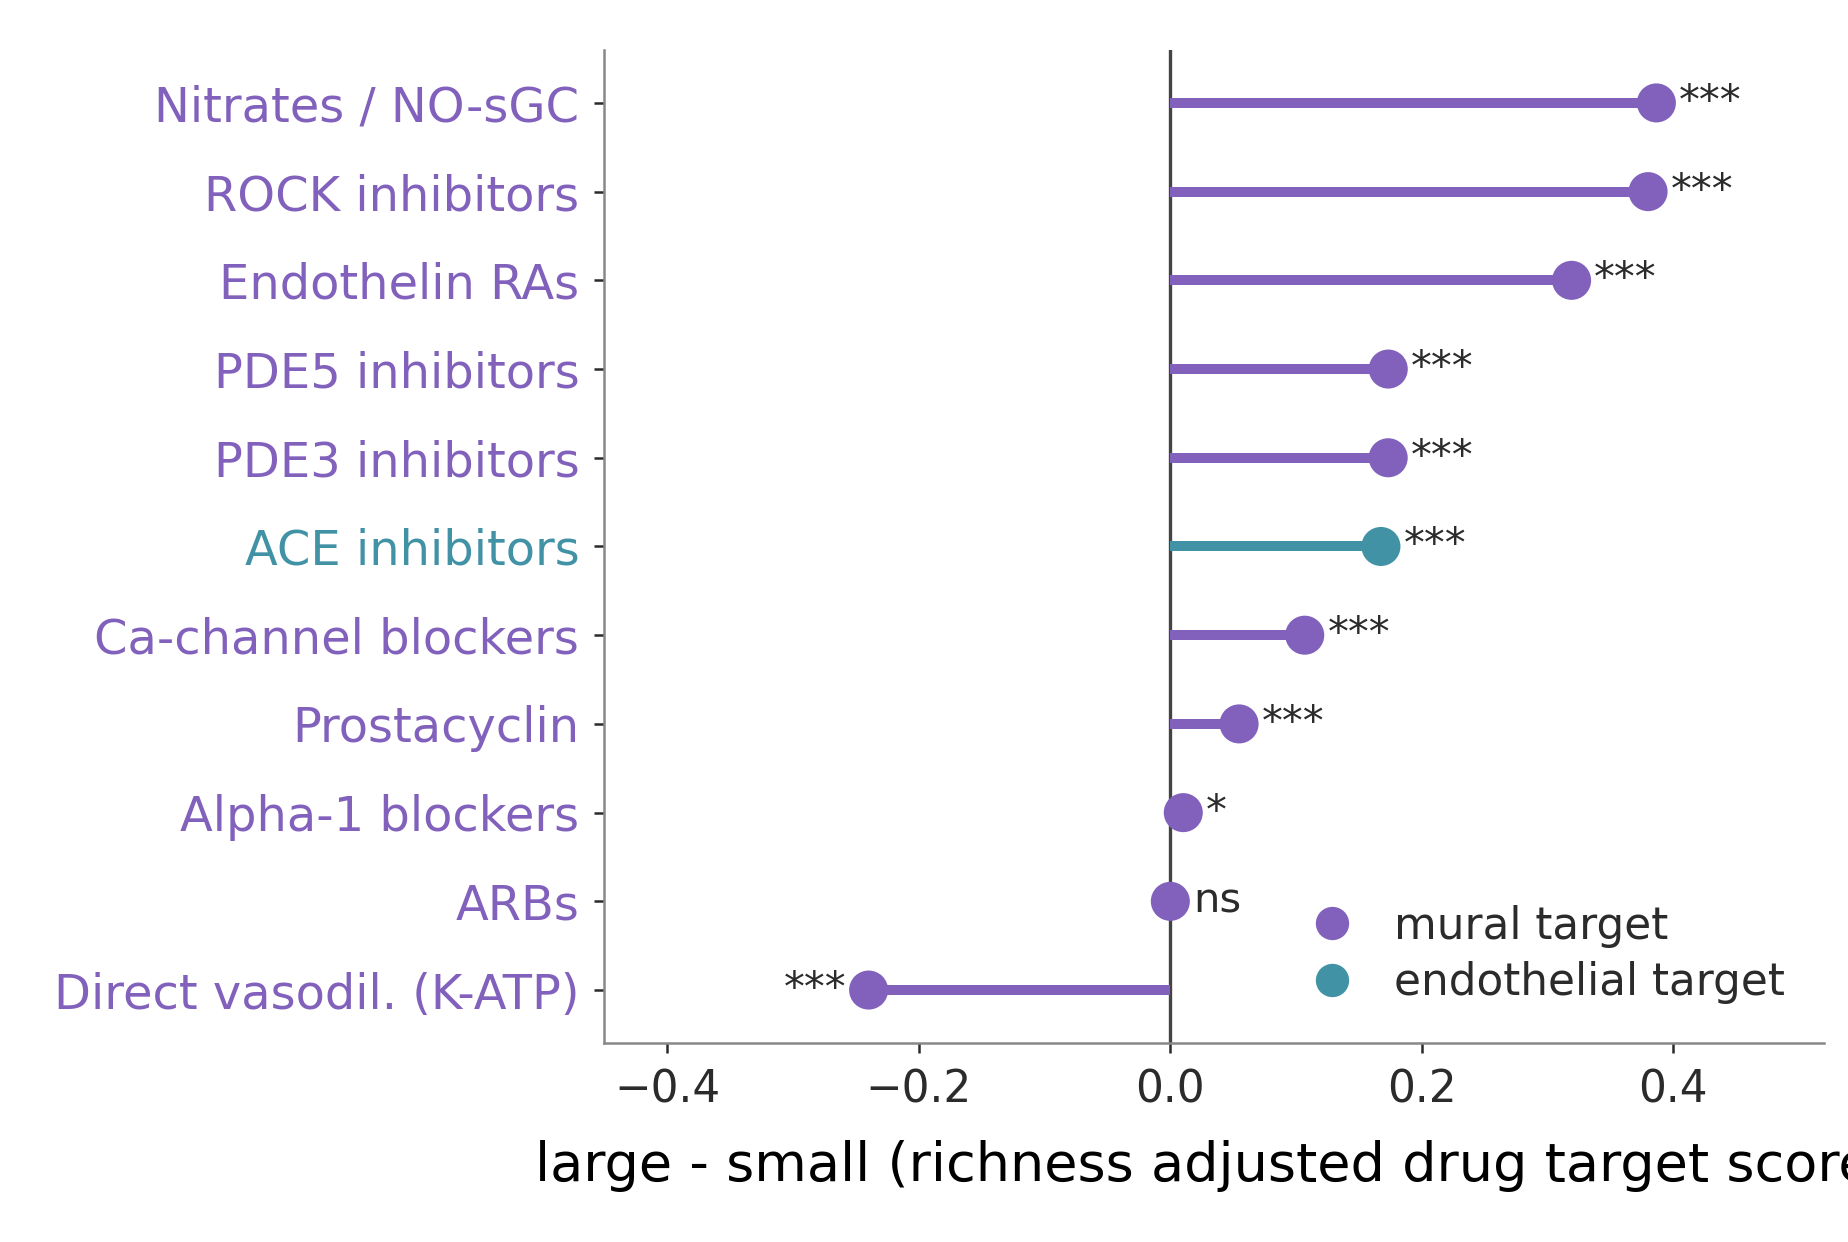

In [41]:
fig = hhca.pl.drug_calibre(selectivity)

Of the 80,520 tested structures, 1,076 are large and 34,083 small. The targets of nine drug classes score higher
in large vessels (adjusted p < 0.05), led by NO–sGC (0.387), ROCK (0.380) and endothelin receptors (0.319), and
they do so on all 11 sections. Targets of angiotensin receptor blockers do not differ (p = 0.97). The K-ATP
channel genes are the only targets that score higher in small vessels after adjustment (−0.240); without the
adjustment, the small vessels score higher on only 4 of the 11 sections.

## An arteriole and a venule on H&E

Finally we look at two structures on the histology. For two sections the H&E image is registered to the Visium HD
grid at native resolution, and the configuration names one arteriole and one venule field of 120 µm on them.

In [42]:
fig4f = cfg["fig4f"]
candidates = pd.DataFrame(fig4f["candidates"]).T
selected = candidates.loc[list(fig4f["selected"].values())]
selected

,slide,klass,struct,x_um,y_um,diam_um
BO_HDZ_myo_art3,VS_BO_HDZ150319_34_myo,arteriole,2466,2131.8,6965.2,51.1
CA_H0054LV_myo_ven1,VS_CA_H0054LV_henricke_myo,venule,10854,7900.4,5543.2,50.3


`hhca.tl.extract_field` cuts a field out of a section: the H&E crop, the 2 µm bins with their Level-3 type, and
the in-tissue bins without a cell type (no decode pixel, or flagged by CMFLAG).

In [43]:
roots = resolve_roots(cfg)
fields = []
bins_per_field = []
for candidate in selected.itertuples():
    he = fig4f["he"][candidate.slide]
    field_pixels = hhca.io.read_decode(section_path(cfg, "decode", candidate.slide), columns=("X", "Y", "K1", "P1"))
    tissue_xy = hhca.io.read_tissue_positions(section_path(cfg, "spaceranger", candidate.slide))
    he_image = tifffile.memmap(fill(he["tif"], roots))
    spillover = spillover_keys(f"{cfg['flags']}/{candidate.slide}_clean_bins.parquet")
    field = hhca.tl.extract_field(
        field_pixels,
        factor_order,
        tissue_xy,
        he_image,
        he["H_um_to_px"],
        (candidate.x_um, candidate.y_um),
        side_um=fig4f["field_um"],
        spillover=spillover,
    )
    fields.append(field)
    bins_per_field.append({"assigned bins": len(field["ax"]), "unassigned bins": len(field["ux"])})
pd.DataFrame(bins_per_field, index=selected.index)

,assigned bins,unassigned bins
BO_HDZ_myo_art3,3220,620
CA_H0054LV_myo_ven1,3148,690


`hhca.pl.vessel_fields` draws Fig 4 f: the vascular bins are filled with their Level-3 colour and the bins
without a cell type are hatched.

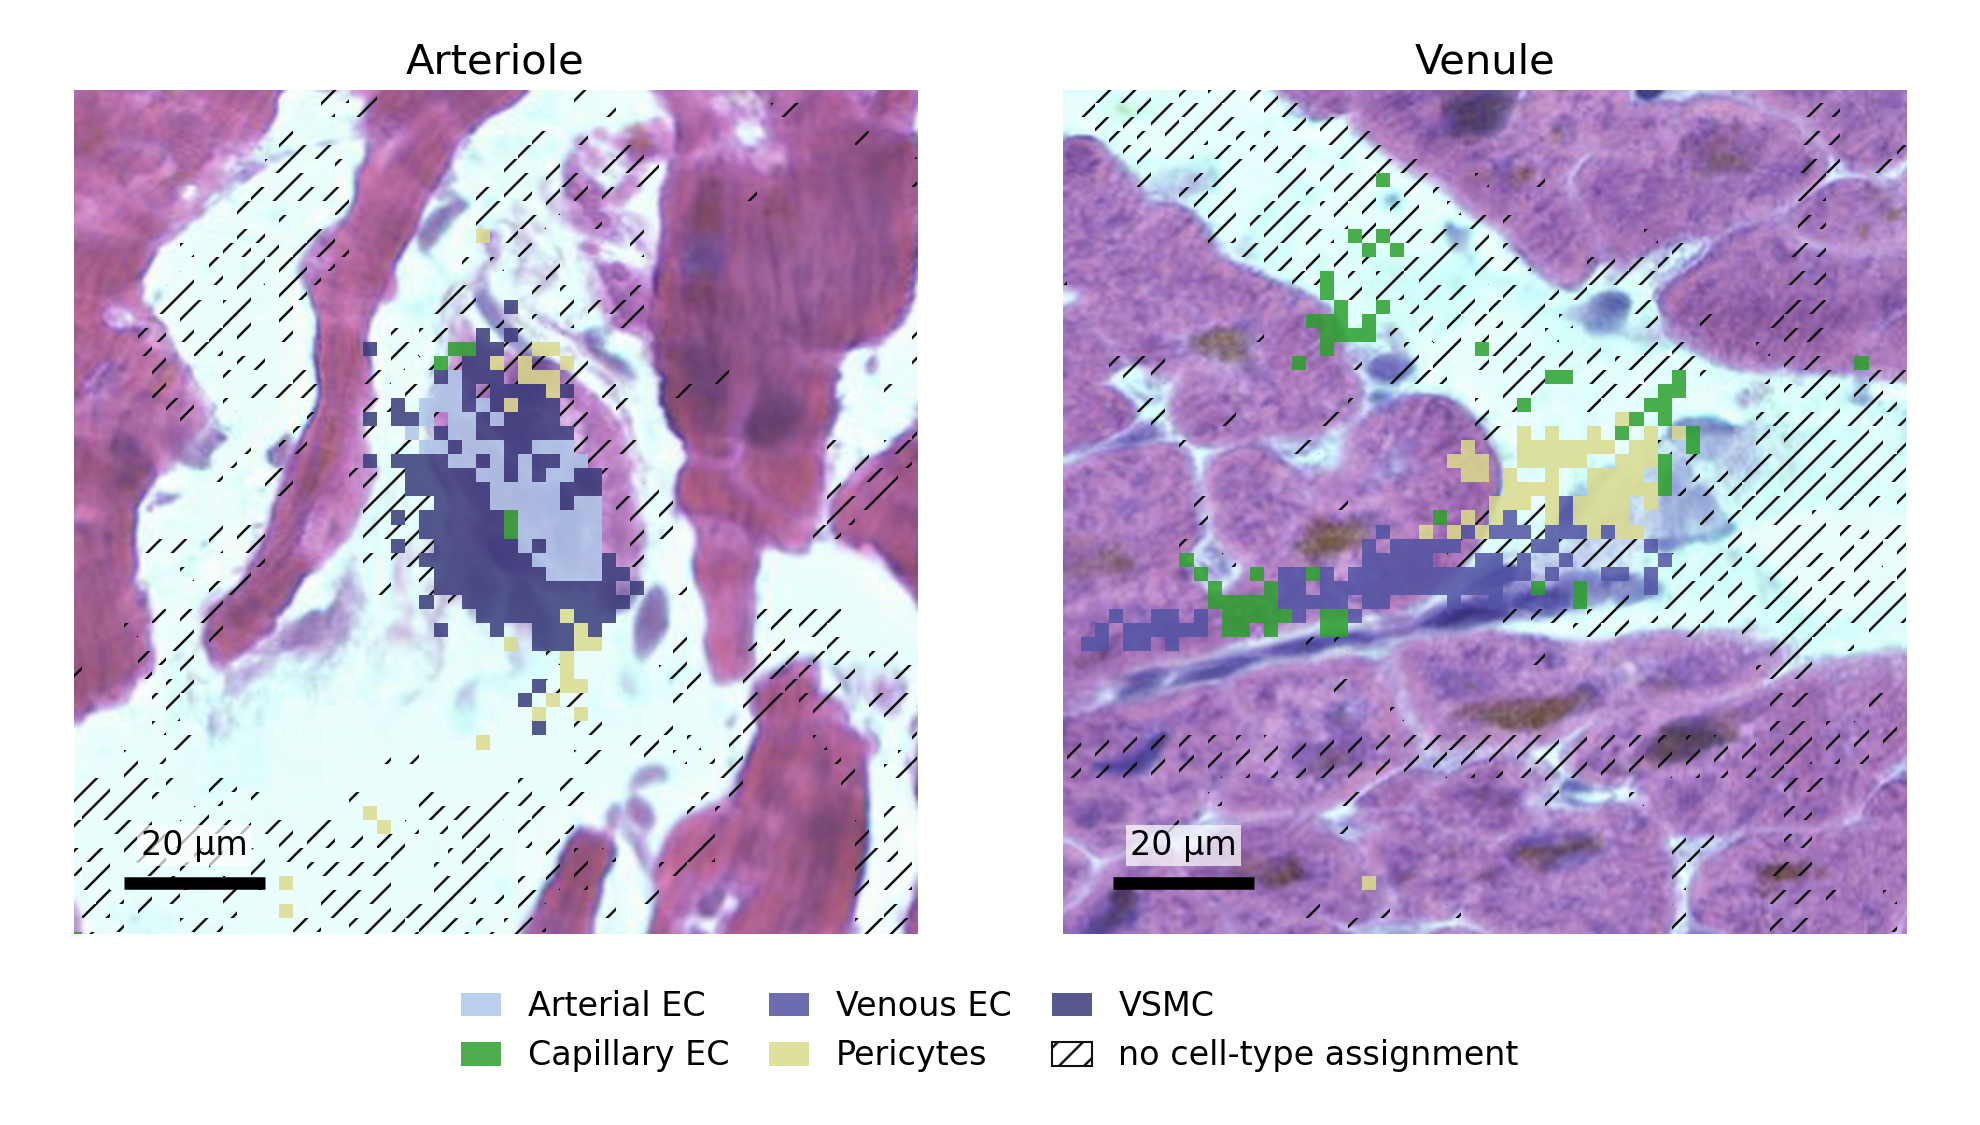

In [44]:
titles = selected["klass"].str.capitalize().tolist()
fig = hhca.pl.vessel_fields(fields, titles, fig4f["show_types"])

In the arteriole field, smooth-muscle and arterial endothelial bins fill the wall of a vessel of 51 µm; in the
venule field, venous endothelial bins line the lumen, with pericytes and capillaries next to it. Of the bins in
the two fields, 3,220 and 3,148 carry a cell type and 620 and 690 do not.

## Key takeaways

- Joining vascular decode pixels on an 8 µm lattice gives 87,792 vessel structures on 11 sections; a
  lumen-inclusive diameter separates 1,095 large, 47,814 intermediate and 38,883 small structures.
- The wall composition follows calibre: smooth muscle and arterial endothelium in large vessels, capillary
  endothelium and pericytes in small ones.
- RAAS genes have their own places along the vascular tree: *ACE* in arterioles, *ENPEP* in muscular arteries and
  *AGT* in capillaries and microvessels.
- The targets of nine of 11 vasoactive drug classes are higher in large vessels on every section; K-ATP channel
  genes are the exception.
- Every step is one function of `hhca.tl` and every panel one function of `hhca.pl`, so the same code runs here
  and in the pipeline scripts.